# 02 - Customer churn analysis

**Customer360 - Customer Retention & Churn Analytics**

Exploratory analysis of what is associated with churn, followed by a summary of the prediction models.
Every chart is followed by an interpretation: *what the data shows*, *why it matters*, and *what a business could do*.
All relationships are **associations in a single snapshot** - they do not prove cause.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, data_cleaning as dc, feature_engineering as fe, exploratory_analysis as eda
pd.set_option("display.width", 160, "display.max_columns", 40)
%matplotlib inline

df = eda.load_features()
net = eda.internet_only(df)
overall = eda.overall_churn(df)
overall

{'customers': 7043, 'churned': 1869, 'retained': 5174, 'churn_rate_pct': 26.54}

## 1. Overall churn

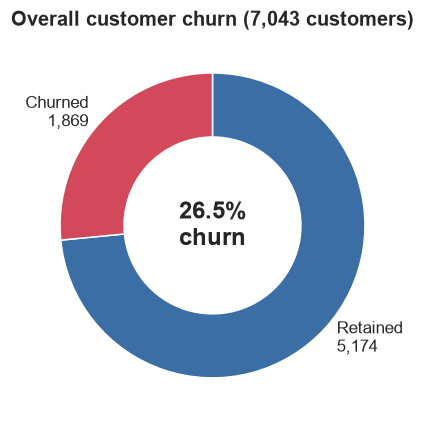

In [2]:
fig = eda.plot_churn_overview(df); display(fig); plt.close(fig)

> **What the data shows.** 1,869 of 7,043 customers (**26.5%**) have churned; 5,174 remain.
>
> **Why it matters.** Roughly one customer in four has left, so the retention problem is material, and the data is imbalanced (74/26) - accuracy alone will be misleading for any model.
>
> **Action to consider.** Treat 26.5% as the benchmark and look for the segments that sit far above it.

## 2. Contract type

,contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


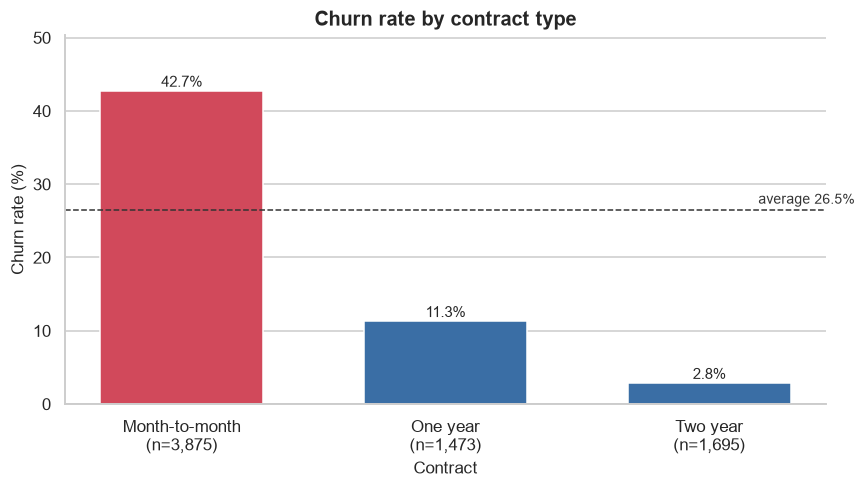

In [3]:
order = config.CONTRACT_ORDER
display(eda.churn_rate_by(df, "contract", order))
fig = eda.plot_churn_rate_bar(df, "contract", "Churn rate by contract type", order, "Contract"); display(fig); plt.close(fig)

> **What the data shows.** Month-to-month customers churn at **42.7%**, one-year at **11.3%** and two-year at **2.8%**. Month-to-month customers are 55% of the base (3,875) but 89% of all churners (1,655 of 1,869).
>
> **Why it matters.** Contract length is the single strongest categorical predictor (Cramer's V = 0.41, section 9) and the model's top permutation feature. Contracts partly *prevent* churn mechanically, but the size of the gap also reflects who chooses a commitment.
>
> **Action to consider.** Offer a discount or perk to migrate month-to-month customers to 12/24-month plans, ideally at months 3-9 when risk is highest; target high-value month-to-month customers first.

## 3. Tenure

,tenure_group,customers,churned,churn_rate_pct
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49-72 months,2239,213,9.51


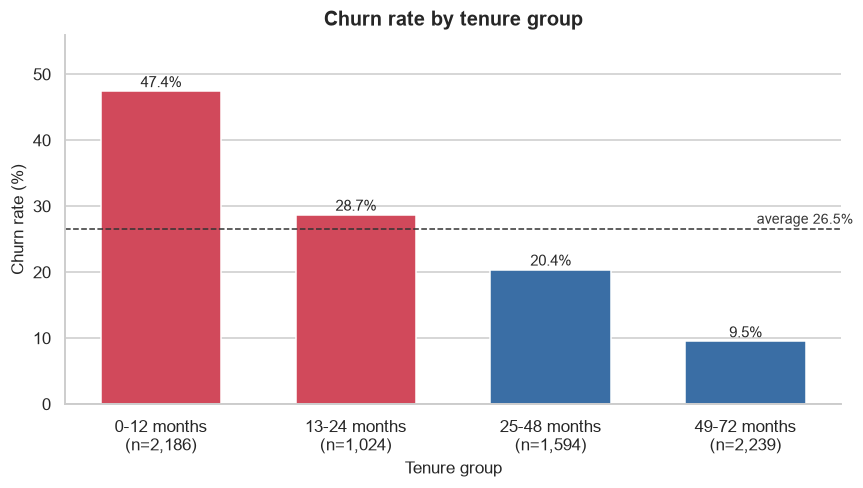

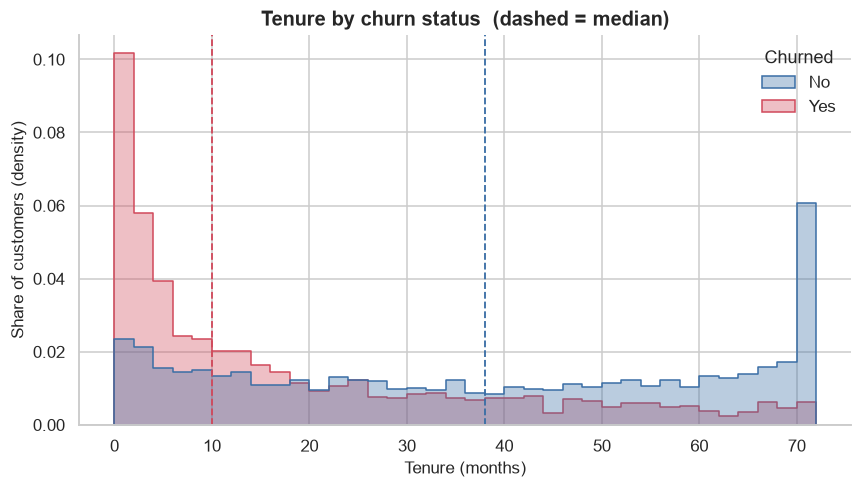

,churn,tenure_months_mean,tenure_months_median
0,No,37.57,38.0
1,Yes,17.98,10.0


Share of churners who left within 12 months of joining: 55.5% | within 6 months: 41.9%


In [4]:
display(eda.churn_rate_by(df, "tenure_group", config.TENURE_LABELS))
fig = eda.plot_churn_rate_bar(df, "tenure_group", "Churn rate by tenure group", config.TENURE_LABELS, "Tenure group"); display(fig); plt.close(fig)
fig = eda.plot_distribution_by_churn(df, "tenure_months", "Tenure by churn status", "Tenure (months)", 36); display(fig); plt.close(fig)
display(eda.numeric_by_churn(df, ["tenure_months"]))
print("Share of churners who left within 12 months of joining:", f"{(df.loc[df.churn_flag == 1, 'tenure_months'] <= 12).mean():.1%}",
      "| within 6 months:", f"{(df.loc[df.churn_flag == 1, 'tenure_months'] <= 6).mean():.1%}")

> **What the data shows.** Churn falls steadily with tenure: **47.4%** in the first year, 28.7%, 20.4%, then **9.5%** after four years. Churned customers had a median tenure of **10 months** versus 38 for retained customers, and **55%** of churners left within 12 months of joining.
>
> **Why it matters.** Most value is lost early. The first year is where retention effort has the best return, and customers who pass it become much more stable.
>
> **Action to consider.** Design a first-year programme: onboarding, 30/90-day check-ins, proactive service follow-up, and early contract-upgrade offers.

## 4. Internet service

,internet_service,customers,churned,churn_rate_pct
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No internet,1526,113,7.40


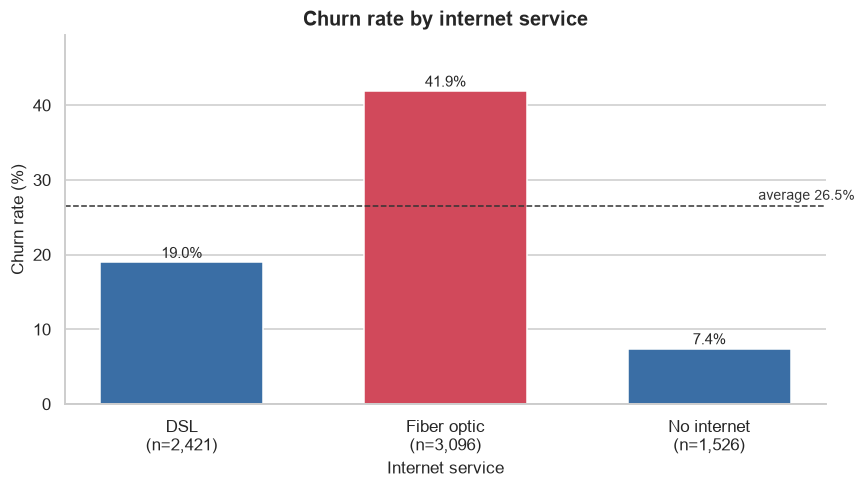

In [5]:
order = ["DSL", "Fiber optic", "No internet"]
display(eda.churn_rate_by(df, "internet_service", order))
fig = eda.plot_churn_rate_bar(df, "internet_service", "Churn rate by internet service", order, "Internet service"); display(fig); plt.close(fig)

> **What the data shows.** Fibre-optic customers churn at **41.9%** versus 19.0% for DSL and 7.4% for customers without internet. Fibre customers are 44% of the base but **69%** of churners.
>
> **Why it matters.** The premium product is the one losing customers. Fibre customers pay more (see section 8) and the gap persists inside every contract type (e.g. month-to-month: fibre 54.6% vs DSL 32.2%), so it is not just a contract effect.
>
> **Action to consider.** Investigate fibre service quality/outages and price-for-value versus competitors; consider a fibre-specific retention offer. The data cannot say *why* fibre customers leave - customer feedback would.

## 5. Payment method and billing

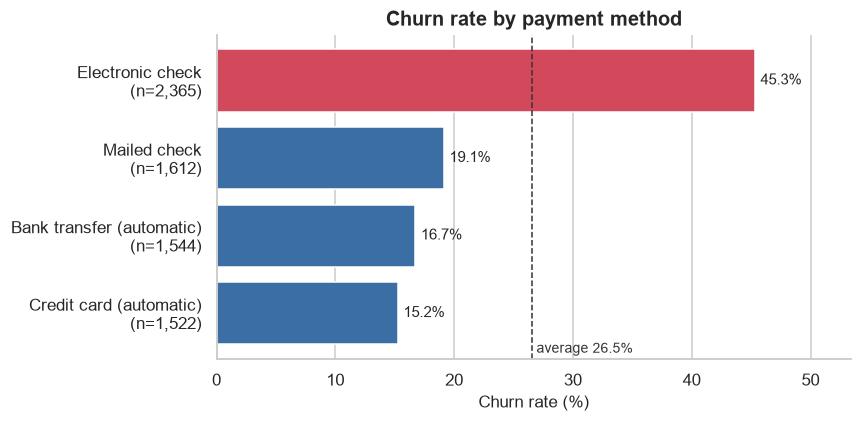

,payment_method,customers,churned,churn_rate_pct (month-to-month only)
0,Electronic check,1850,994,53.73
1,Bank transfer (automatic),589,201,34.13
2,Credit card (automatic),543,178,32.78
3,Mailed check,893,282,31.58


,paperless_billing,customers,churned,churn_rate_pct
0,Yes,4171,1400,33.57
1,No,2872,469,16.33


In [6]:
fig = eda.plot_churn_rate_bar(df, "payment_method", "Churn rate by payment method", None, "", True); display(fig); plt.close(fig)
mtm = df[df.contract == "Month-to-month"]
display(eda.churn_rate_by(mtm, "payment_method").rename(columns={"churn_rate_pct": "churn_rate_pct (month-to-month only)"}))
display(eda.churn_rate_by(df, "paperless_billing"))

> **What the data shows.** Electronic-check payers churn at **45.3%** versus 15-19% for every other method (automatic card/bank 15-17%). Only a part of this is explained by contract: among month-to-month customers alone, electronic check is still **53.7%** versus 32-34% for other methods. Paperless billing customers churn at 33.6% versus 16.3% (overall; the gap persists within each contract in the SQL analysis, Q15).
>
> **Why it matters.** A manual, recurring payment step gives customers a regular moment to reconsider, while automatic payment is a form of low-friction commitment. Electronic-check payers are one third of the customer base (2,365).
>
> **Action to consider.** Offer a one-off bill credit for switching to automatic payment, and make the first electronic-check payment experience as easy as possible. Test, don't assume, that it reduces churn.

## 6. Senior citizens

,senior_citizen,customers,churned,churn_rate_pct
0,No,5901,1393,23.61
1,Yes,1142,476,41.68


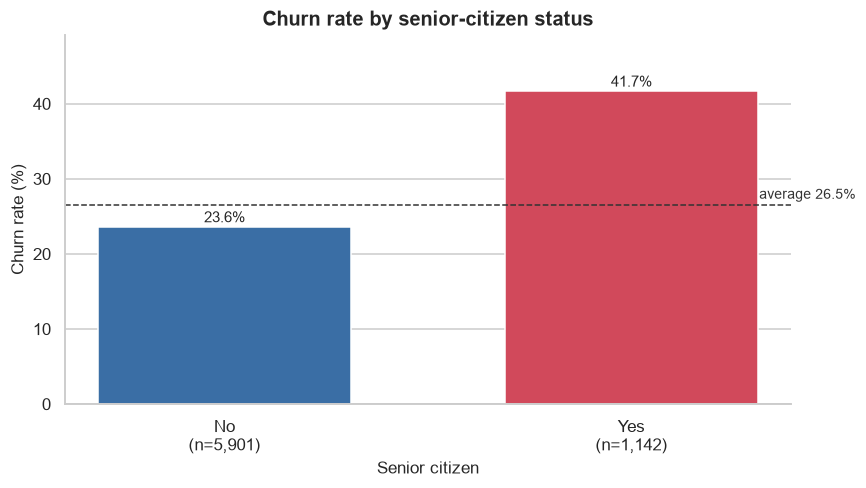

,customers,avg_monthly,pct_fiber,pct_month_to_month
senior_citizen,,,,
No,5901,61.8,38.4,52.0
Yes,1142,79.8,72.8,70.7


In [7]:
display(eda.churn_rate_by(df, "senior_citizen", ["No", "Yes"]))
fig = eda.plot_churn_rate_bar(df, "senior_citizen", "Churn rate by senior-citizen status", ["No", "Yes"], "Senior citizen"); display(fig); plt.close(fig)
cmp = df.groupby("senior_citizen").agg(customers=("customer_id", "count"), avg_monthly=("monthly_charges", "mean"),
        pct_fiber=("internet_service", lambda s: (s == "Fiber optic").mean() * 100),
        pct_month_to_month=("contract", lambda s: (s == "Month-to-month").mean() * 100)).round(1)
display(cmp)

> **What the data shows.** Senior citizens (16% of customers) churn at **41.7%** versus 23.6%. They are more likely to be on fibre (72.8% vs 38.4%), on month-to-month contracts (70.7% vs 52.0%), and pay about $18 more per month.
>
> **Why it matters.** Much of the senior gap overlaps with product mix and contract choice, but even within month-to-month customers seniors churn more (54.6% vs 39.6%).
>
> **Action to consider.** Review whether senior customers get adequate support (only 23.9% of seniors with internet have tech support vs 40.3%) and consider a dedicated onboarding/assistance offer.

## 7. Customer support and add-on services

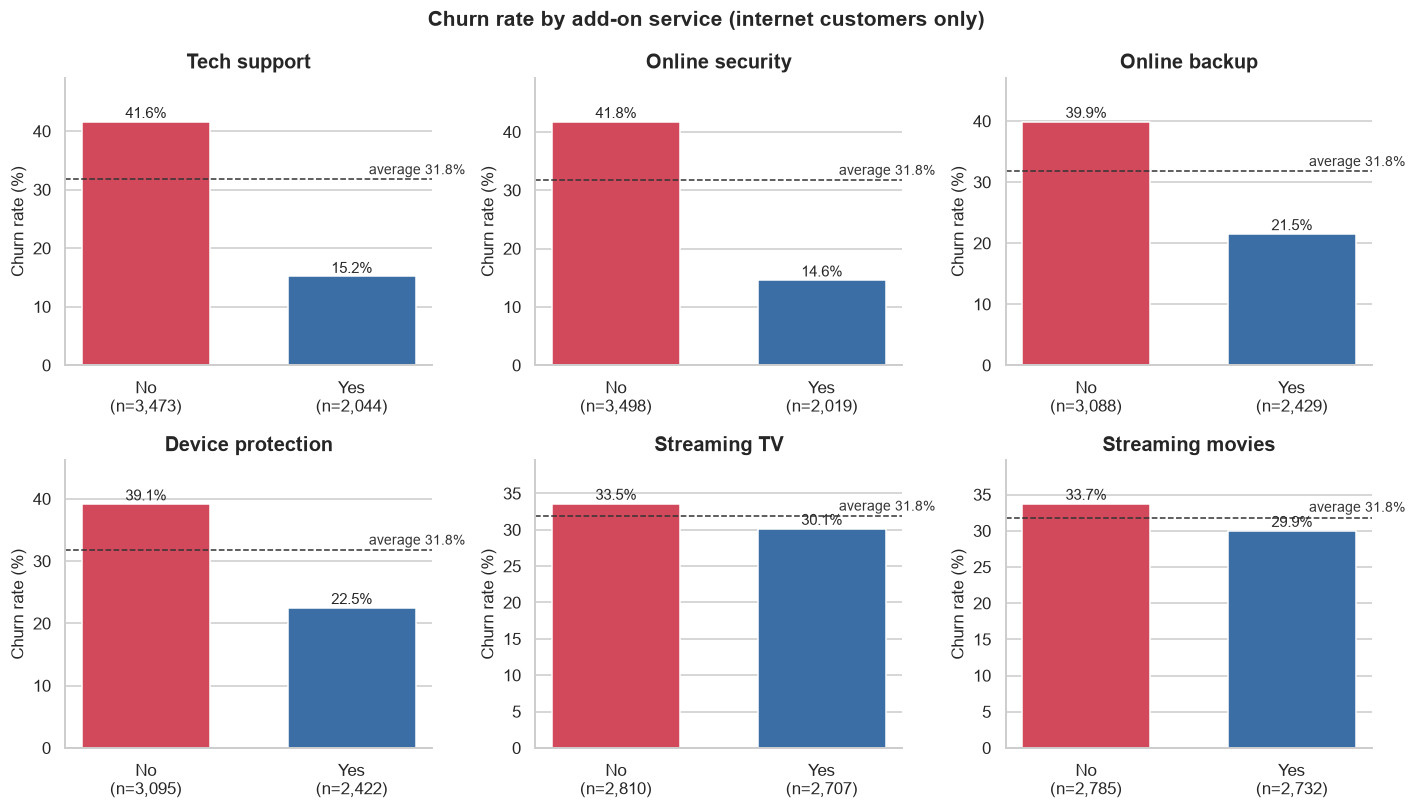

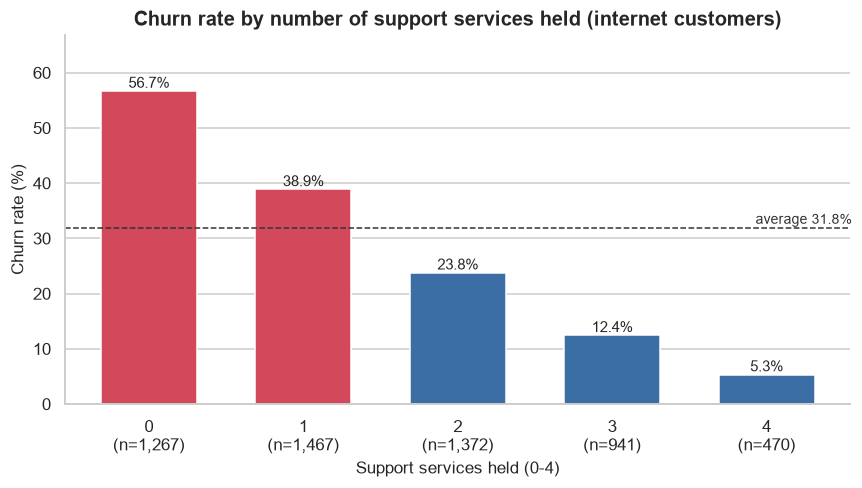

In [8]:
fig = plt.figure(figsize=(13, 7.5))
support = {"tech_support": "Tech support", "online_security": "Online security", "online_backup": "Online backup",
           "device_protection": "Device protection", "streaming_tv": "Streaming TV", "streaming_movies": "Streaming movies"}
for i, (col, label) in enumerate(support.items(), 1):
    ax = fig.add_subplot(2, 3, i)
    eda.plot_churn_rate_bar(net, col, label, ["No", "Yes"], "", False, ax=ax)
fig.suptitle("Churn rate by add-on service (internet customers only)", fontsize=14, fontweight="bold")
fig.tight_layout(); display(fig); plt.close(fig)
fig = eda.plot_churn_rate_bar(net, "num_support_services", "Churn rate by number of support services held (internet customers)",
                              None, "Support services held (0-4)"); display(fig); plt.close(fig)

> **What the data shows.** Among internet customers, those **with tech support churn at 15.2% vs 41.6% without**; online security 14.6% vs 41.8%. Streaming services show almost no difference (30-34%). Churn falls with each support service held: **56.7%** with none, 38.9%, 23.8%, 12.4%, and **5.3%** with all four.
>
> **Why it matters.** Protection and support services are strongly associated with retention while entertainment add-ons are not. This is association: customers who value the service may be more engaged to begin with, and tenure is correlated with holding more services.
>
> **Action to consider.** Bundle or trial a support/security service for internet customers who have none (549 active customers on $35K of monthly revenue, SQL Q18); run an A/B test to measure the real effect.

## 8. Monthly charges and the charges / tenure relationship

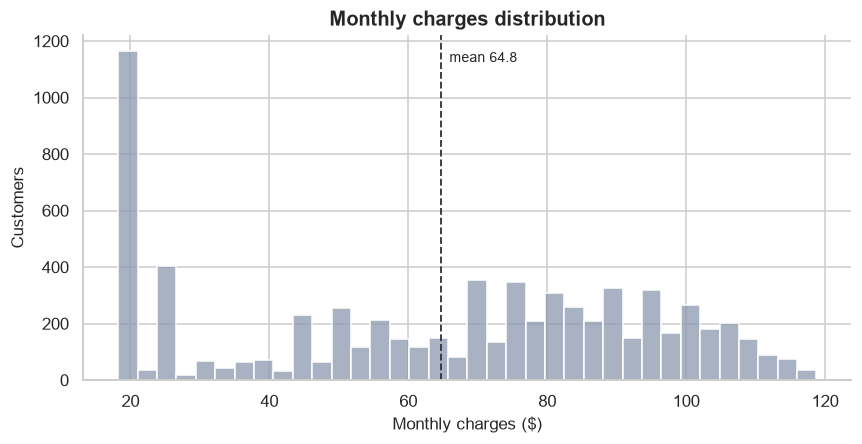

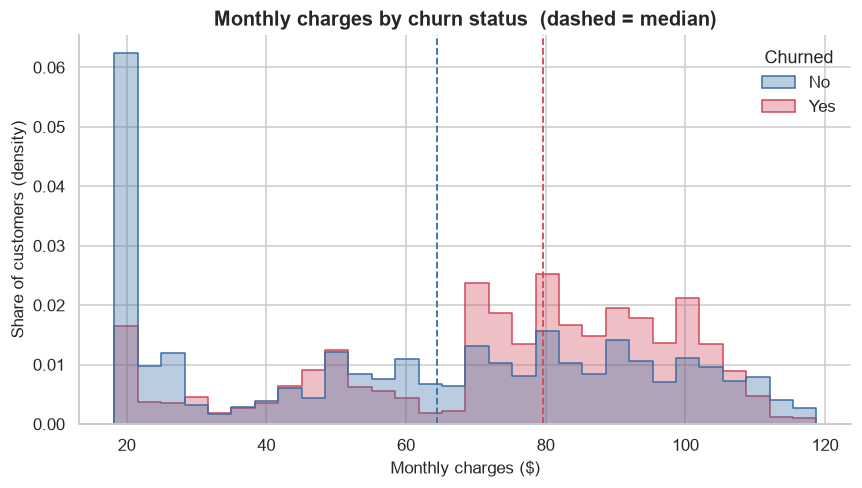

,monthly_charge_band,customers,churned,churn_rate_pct
0,<$35,1731,188,10.86
1,$35-70,1721,407,23.65
2,$70-90,1847,701,37.95
3,$90+,1744,573,32.86


,churn,monthly_charges_mean,monthly_charges_median
0,No,61.27,64.43
1,Yes,74.44,79.65


Customers paying under $25: 1389 of which no internet: 1350


In [9]:
fig = eda.plot_single_distribution(df, "monthly_charges", "Monthly charges distribution", "Monthly charges ($)"); display(fig); plt.close(fig)
fig = eda.plot_distribution_by_churn(df, "monthly_charges", "Monthly charges by churn status", "Monthly charges ($)"); display(fig); plt.close(fig)
display(eda.churn_rate_by(df, "monthly_charge_band", config.CHARGE_LABELS))
display(eda.numeric_by_churn(df, ["monthly_charges"]))
print("Customers paying under $25:", int((df.monthly_charges < 25).sum()), "of which no internet:", int(((df.monthly_charges < 25) & (df.internet_service == "No internet")).sum()))

> **What the data shows.** Monthly charges are bimodal: a cluster of about 1,400 customers pays under $25 (almost all phone-only, no internet) and the rest spread across $35-$120. Churned customers pay more: **$74.44 vs $61.27** on average (median $79.65 vs $64.43). Churn is 10.9% below $35, rising to **38.0%** at $70-90 and 32.9% above $90.
>
> **Why it matters.** Price level alone is a weak, non-linear signal - the cheapest customers (mostly phone-only) are loyal, and the most expensive are mostly fibre customers with many add-ons.
>
> **Action to consider.** Do not blanket-discount: target price relief or value-adds at customers paying $70+ who are also new or on month-to-month contracts (next section).

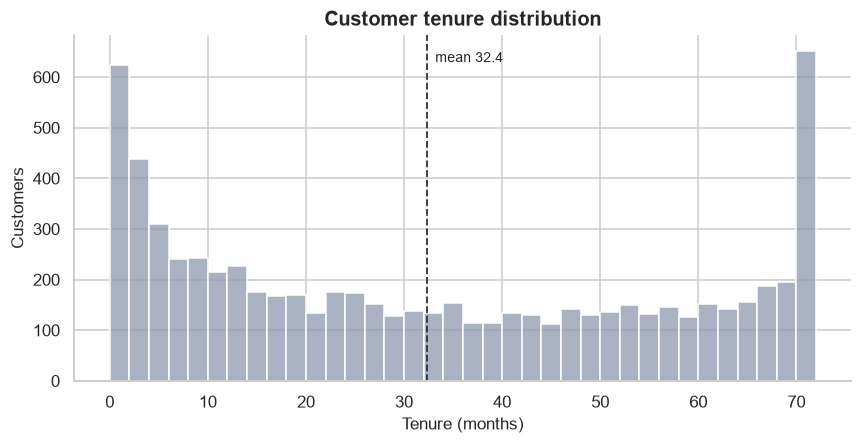

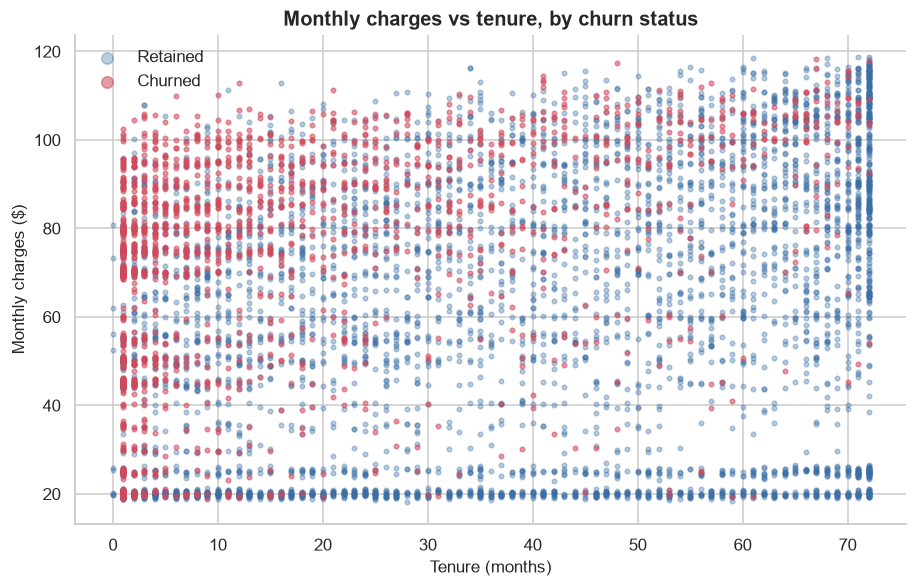

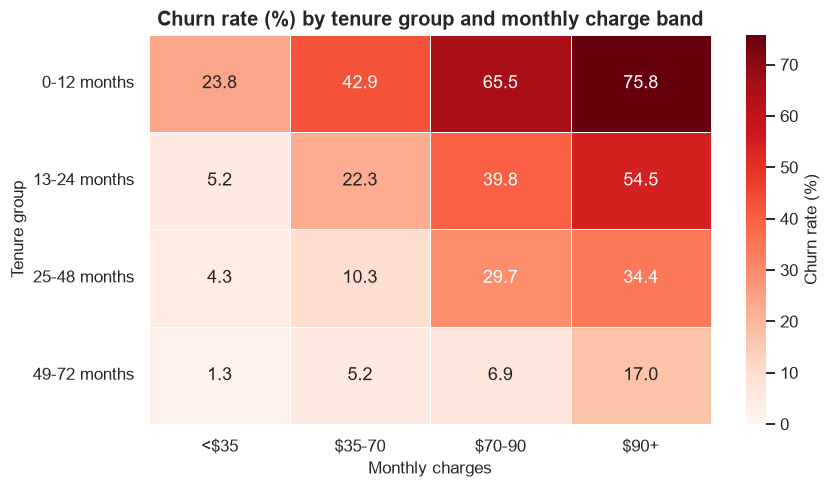

tenure_months     -0.35
monthly_charges    0.19
total_charges     -0.20
churn_flag         1.00
Name: churn_flag, dtype: float64


In [10]:
fig = eda.plot_single_distribution(df, "tenure_months", "Customer tenure distribution", "Tenure (months)", 36); display(fig); plt.close(fig)
fig = eda.plot_charges_vs_tenure(df); display(fig); plt.close(fig)
hm = eda.churn_heatmap_table(df, "tenure_group", "monthly_charge_band", config.TENURE_LABELS, config.CHARGE_LABELS)
fig = eda.plot_heatmap(hm, "Churn rate (%) by tenure group and monthly charge band", "Monthly charges", "Tenure group"); display(fig); plt.close(fig)
print(df[["tenure_months", "monthly_charges", "total_charges", "churn_flag"]].corr().round(2)["churn_flag"])

> **What the data shows.** Tenure is U-shaped (about 31% of customers are in their first year and 32% are past four years). The charges-tenure heatmap shows the combined effect: **new customers paying $90+ churn at 75.8%** and those paying $70-90 at 65.5%, whereas long-tenure customers paying under $35 churn at 1.3%. Correlation with churn: tenure -0.35, monthly charges +0.19.
>
> **Why it matters.** Price sensitivity is concentrated in the first year: the same high price is tolerated by established customers but not by new ones.
>
> **Action to consider.** Prioritise new high-spend customers (880 customers, 68% churn in SQL Q08) for onboarding, price-for-value reassurance and early contract offers.

## 9. Which categorical features are most associated with churn?

,feature,cramers_v,p_value
0,contract,0.410,5.863038e-258
1,tenure_group,0.349,2.943770e-185
2,internet_service,0.322,9.571788e-160
3,payment_method,0.303,3.682355e-140
4,monthly_charge_band,0.234,4.418356e-83
5,is_autopay,0.210,1.872491e-69
6,paperless_billing,0.192,2.614597e-58
7,online_security,0.171,8.011674e-47
8,tech_support,0.165,1.935257e-43
9,dependents,0.164,3.276083e-43


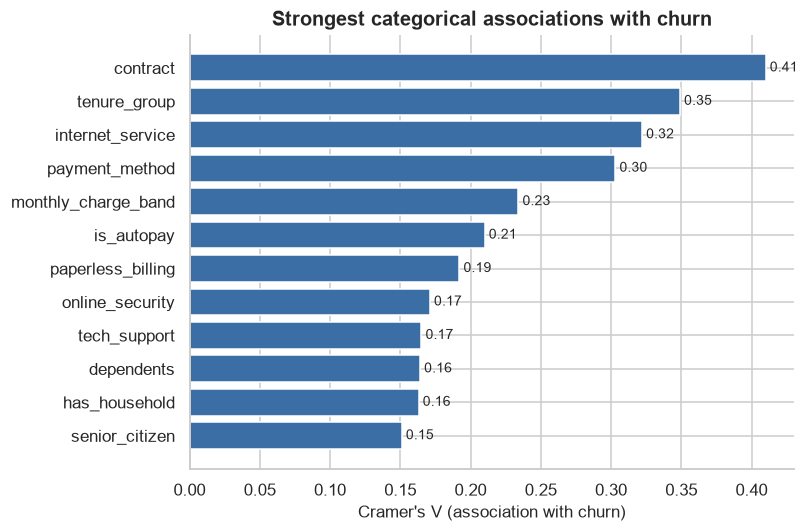

gender Cramer's V: 0.009


In [11]:
cat_cols = fe.CATEGORICAL_FEATURES + ["tenure_group", "monthly_charge_band", "is_autopay", "has_support_service", "has_household"]
assoc = eda.association_with_churn(df, cat_cols)
display(assoc.head(10))
fig = eda.plot_association_ranking(assoc); display(fig); plt.close(fig)
print("gender Cramer's V:", float(assoc.set_index("feature").loc["gender", "cramers_v"]))

> **What the data shows.** Contract (V = 0.41), tenure group (0.35), internet service (0.32) and payment method (0.30) have the strongest associations with churn; gender is essentially unrelated (V < 0.01).
>
> **Why it matters.** A handful of contract, tenure, product and billing attributes carry most of the signal - the same drivers the models later rely on.
>
> **Action to consider.** Build retention segments from these attributes rather than from demographics such as gender.

## 10. Highest-risk combinations

Combining contract, internet service and tenure isolates where churn is concentrated.

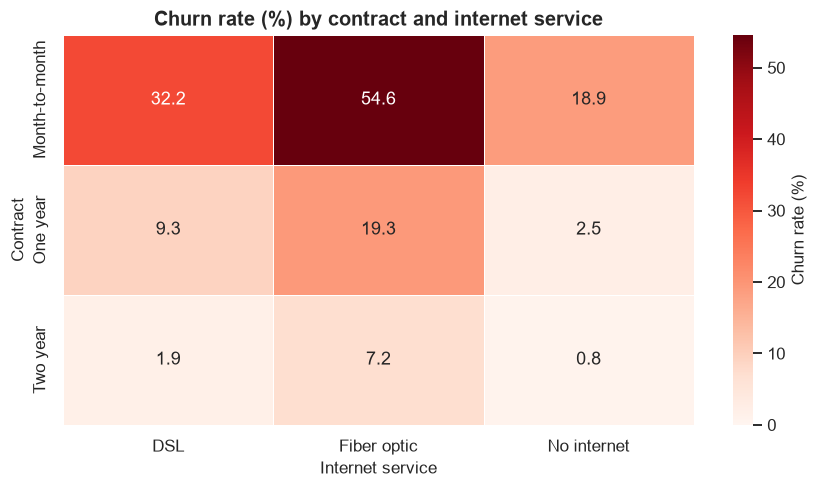

customers  churned  churn_rate_pct
contract       tenure_group internet_service                                    
Month-to-month 0-12 months  Fiber optic             916      643            70.2
               13-24 months Fiber optic             425      215            50.6
               25-48 months Fiber optic             521      226            43.4
               0-12 months  DSL                     690      293            42.5
               49-72 months Fiber optic             266       78            29.3
               13-24 months DSL                     232       55            23.7

In [12]:
hm2 = eda.churn_heatmap_table(df, "contract", "internet_service", config.CONTRACT_ORDER, ["DSL", "Fiber optic", "No internet"])
fig = eda.plot_heatmap(hm2, "Churn rate (%) by contract and internet service", "Internet service", "Contract"); display(fig); plt.close(fig)
seg = df.groupby(["contract", "tenure_group", "internet_service"], observed=True)["churn_flag"].agg(customers="count", churned="sum")
seg["churn_rate_pct"] = (seg.churned / seg.customers * 100).round(1)
top = seg[seg.customers >= 50].sort_values("churn_rate_pct", ascending=False).head(6)
top

> **What the data shows.** **Month-to-month + fibre** customers churn at 54.6%; month-to-month + fibre + first year reaches **70.2%** (916 customers, 643 churners = 34% of all churners). One- and two-year contracts hold churn below 20% for every internet type.
>
> **Why it matters.** A single, identifiable group - new fibre customers without a contract commitment - accounts for about a third of all churn.
>
> **Action to consider.** Make this group the pilot population for retention offers; it is large enough to measure results and small enough to act on.

## 11. Machine-learning summary

Full details in `reports/model_results.md`. Models were trained with leak-free pipelines (preprocessing fitted per fold), a stratified 80/20 split and 5-fold CV.

In [13]:
tm = pd.read_csv(config.REPORTS_DIR / "tables" / "test_metrics.csv")
display(tm[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(3))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.805,0.656,0.556,0.602,0.842
1,Logistic Regression (balanced),0.739,0.505,0.786,0.615,0.842
2,Random Forest,0.797,0.649,0.513,0.573,0.844
3,Random Forest (balanced),0.769,0.549,0.725,0.624,0.843
4,XGBoost,0.803,0.663,0.521,0.584,0.844
5,XGBoost (balanced),0.747,0.516,0.791,0.624,0.843
6,Majority-class baseline,0.735,0.000,0.000,0.000,0.500


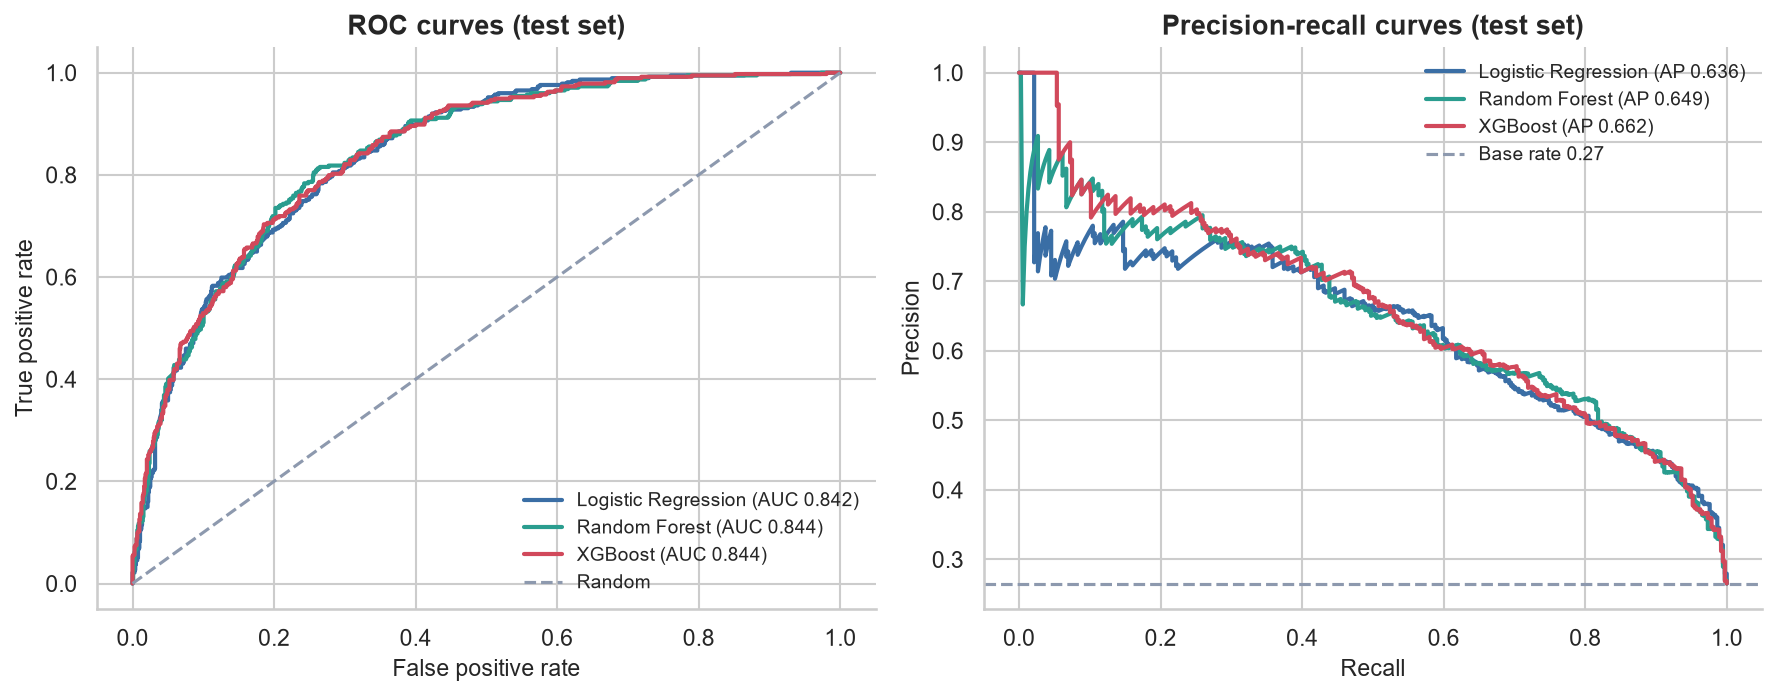

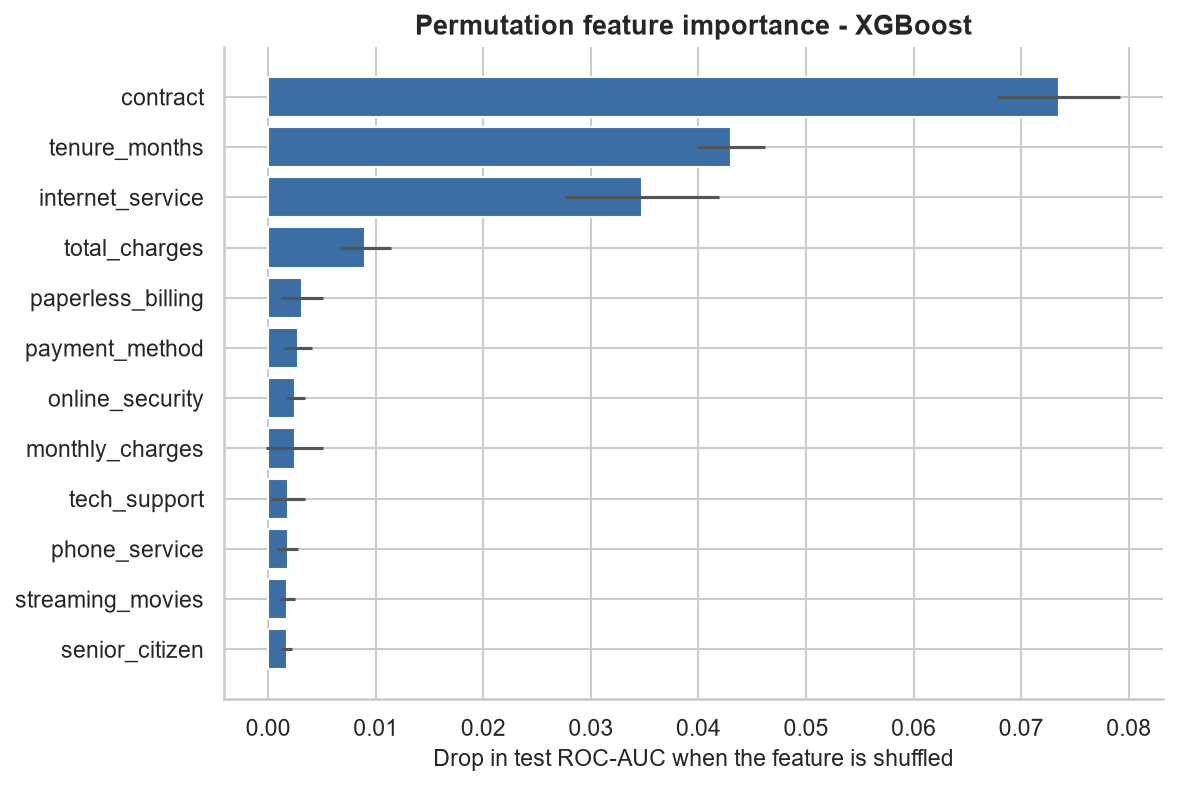

In [14]:
from IPython.display import Image
for f in ["ml_01_roc_pr_curves.png", "ml_04_permutation_importance.png"]:
    display(Image(filename=str(config.FIGURES_DIR / f)))

**Interpretation.** On the hold-out test set all models rank customers similarly (ROC-AUC about 0.84). Accuracy (74-81%) must not be read alone:
a model that predicts nobody churns scores 73.5% accuracy. Class-weighted versions trade precision for much higher recall (up to ~79%).
Permutation importance confirms the EDA: **contract, tenure and internet service** dominate, followed by total charges, billing and payment attributes.

## 12. Limitations

* Single snapshot with no dates: no time-to-event modelling and no way to check seasonality or recent trends.
* Associations only - e.g. support services and churn are related, but the data cannot show that adding a service *causes* retention.
* No cost / margin data, so recommendations are sized by revenue, not profit.
* One public sample dataset; results may not transfer to another operator.